# Circuit resources: encoding strategies, reservoirs and result getters

This notebook takes one example sequence from the data and builds the circuits our quantum feature pipeline would run on it:

1. One encoding circuit per encoding strategy (`su`, Heisenberg, ZZ).
2. One step of a multi-circuit quantum reservoir for each encoding strategy.
3. A table of the depth of every circuit after transpiling for IBM Torino.
4. A discussion of how many circuit executions and shots each result getter needs.

Nothing here runs on hardware. Depths come from transpiling against `FakeTorino`, a snapshot of the real `ibm_torino` gate set, coupling map and calibration data, so no IBM account is needed.

In [1]:
# ---- Example sequence ----
TARGET = "INDPRO"     # which Track B predictor set to use
WINDOW = 12           # months per reservoir sequence, as in scripts/build_quantum_tracks.py
END_DATE = None       # last month of the example window; None = last month in the data

# ---- Reservoir ----
NUM_HIDDEN = 6        # hidden-state features carried between multi-circuit reservoir steps
NUM_TROTTER_STEPS = 6 # Trotter steps for the Heisenberg and ZZ encodings
SEED = 42

# ---- Transpilation ----
OPTIMIZATION_LEVEL = 3

## Setup

In [2]:
from pathlib import Path

import numpy as np
import pandas as pd
from qiskit.circuit.library import efficient_su2
from qiskit.quantum_info import SparsePauliOp
from qiskit.transpiler import generate_preset_pass_manager
from qiskit_ibm_runtime.fake_provider import FakeTorino

from src.features.quantum import multi_circuit_quantum_reservoir
from src.features.quantum.encoding_strategy import su_encoding_strategy, heisenberg_encoding_strategy
from src.features.quantum.result_getters import (
    pce_result_getter,
    single_qubit_pauli_result_getter,
    single_bit_sampler_result_getter,
    bitstring_probability_result_getter,
)

REPO_ROOT = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / "pyproject.toml").exists())
DATA_DIR = REPO_ROOT / "data" / "processed"

backend = FakeTorino()
pass_manager = generate_preset_pass_manager(
    optimization_level=OPTIMIZATION_LEVEL, backend=backend, seed_transpiler=SEED
)
print(f"{backend.name}: {backend.num_qubits} qubits, basis gates {sorted(backend.operation_names)}")

fake_torino: 133 qubits, basis gates ['cz', 'delay', 'for_loop', 'id', 'if_else', 'measure', 'reset', 'rz', 'switch_case', 'sx', 'x']


## Example sequence

Track B inputs are min-max scaled with expanding (causal) statistics, the same way `scripts/build_quantum_tracks.py` scales them, so every encoding strategy below uses `scale=False`. The example sequence is the trailing `WINDOW` months ending at `END_DATE`: one reservoir input.

In [3]:
def causal_minmax(df: pd.DataFrame) -> pd.DataFrame:
    # Same as scripts/build_quantum_tracks.py: scale with min/max over rows up to and including t.
    lo, hi = df.expanding().min(), df.expanding().max()
    return ((df - lo) / (hi - lo).replace(0, np.nan)).fillna(0.5).clip(0, 1)


inputs = pd.read_parquet(DATA_DIR / f"track_b_{TARGET}.parquet").sort_index()
scaled = causal_minmax(inputs)

end = scaled.index[-1] if END_DATE is None else pd.Timestamp(END_DATE)
sequence = scaled.loc[:end].iloc[-WINDOW:]
example_row = sequence.iloc[[-1]]
NUM_FEATURES = sequence.shape[1]

print(f"{TARGET}: {NUM_FEATURES} features, sequence {sequence.index[0]:%Y-%m} to {sequence.index[-1]:%Y-%m}")
sequence.round(3)

INDPRO: 10 features, sequence 2025-03 to 2026-02


,INDPRO,IPMANSICS,CUMFNS,AWHMAN,AMDMNOx,CMRMTSPLx,PERMIT,S&P 500,GS10,TB3MS
date,,,,,,,,,,
2025-03-01,0.687,0.707,0.702,0.745,0.659,0.670,0.684,0.490,0.472,0.636
2025-04-01,0.694,0.684,0.676,0.706,0.360,0.578,0.657,0.501,0.522,0.640
2025-05-01,0.682,0.684,0.676,0.725,0.829,0.587,0.645,0.899,0.564,0.645
2025-06-01,0.715,0.702,0.696,0.725,0.296,0.623,0.644,0.776,0.510,0.636
2025-07-01,0.710,0.708,0.703,0.745,0.445,0.632,0.630,0.794,0.525,0.642
2025-08-01,0.677,0.690,0.682,0.725,0.568,0.593,0.614,0.719,0.484,0.621
2025-09-01,0.692,0.690,0.682,0.725,0.518,0.568,0.654,0.747,0.481,0.611
2025-10-01,0.668,0.657,0.645,0.745,0.460,0.610,0.652,0.734,0.504,0.625
2025-11-01,0.698,0.701,0.695,0.784,0.617,0.606,0.642,0.670,0.531,0.633


## Encoding strategies

Each strategy turns one row of features into the parameter values of a fixed circuit.

- `su_encoding_strategy`: an `efficient_su2` circuit with `ry` and `rx` rotations. Qubits are sized as in `scripts/build_quantum_tracks.py`, âŒˆfeatures / 2âŒ‰, so 10 features use 5 qubits. With `reps=1` the circuit has two rotation layers (20 parameters), so the second layer is zero-padded.
- `heisenberg_encoding_strategy`: Haar-random single-qubit states, then a Trotterized Heisenberg evolution where feature k sets the XX + YY + ZZ coupling between qubits k and k+1. 10 features need 11 qubits.
- ZZ: the same Trotterized evolution with only ZZ couplings (`paulis=("ZZ",)`), the chain version of a ZZ Pauli feature map.

The factories below take the number of features to encode, so the same definitions build the reservoir encodings later, which also carry the hidden state.

In [4]:
def su_factory(n_features):
    return su_encoding_strategy(
        n_qubits=int(np.ceil(n_features / 2)), reps=1, su2_gates=["ry", "rx"], entanglement="full", scale=False
    )


def heisenberg_factory(n_features):
    return heisenberg_encoding_strategy(
        n_features=n_features, num_trotter_steps=NUM_TROTTER_STEPS, seed=SEED, scale=False
    )


def zz_factory(n_features):
    return heisenberg_encoding_strategy(
        n_features=n_features, num_trotter_steps=NUM_TROTTER_STEPS, paulis=("ZZ",), seed=SEED, scale=False
    )


ENCODINGS = {"su": su_factory, "heisenberg": heisenberg_factory, "zz": zz_factory}

encoding_pubs = {name: factory(NUM_FEATURES).generate_pubs(example_row)[0] for name, factory in ENCODINGS.items()}
for name, (circ, params) in encoding_pubs.items():
    print(f"{name:>10}: {circ.num_qubits} qubits, {circ.num_parameters} parameters, {dict(circ.count_ops())}")

        su: 5 qubits, 20 parameters, {'ry': 10, 'rx': 10, 'cx': 10}
heisenberg: 11 qubits, 10 parameters, {'rzz': 60, 'rxx': 60, 'ryy': 60, 'unitary': 11}
        zz: 11 qubits, 10 parameters, {'rzz': 60, 'unitary': 11}


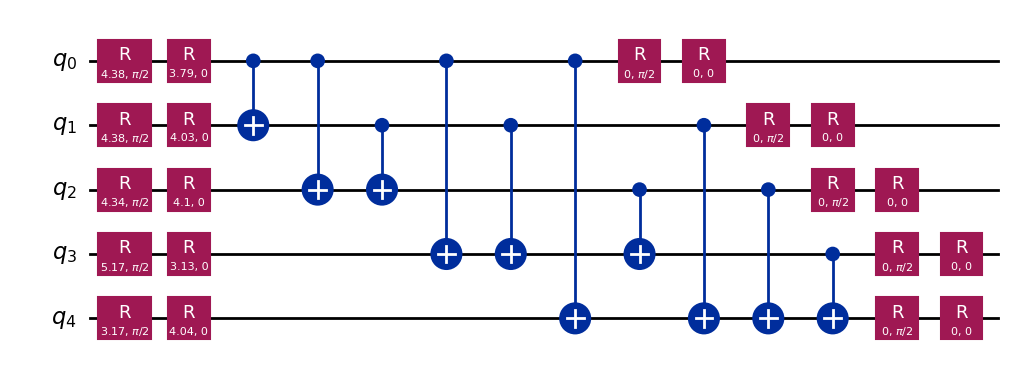

In [5]:
circ, params = encoding_pubs["su"]
circ.assign_parameters(params).decompose().draw("mpl", fold=-1)

The Heisenberg and ZZ circuits repeat the same Trotter step `NUM_TROTTER_STEPS` times (every other step reversed), so only the first two steps are drawn.

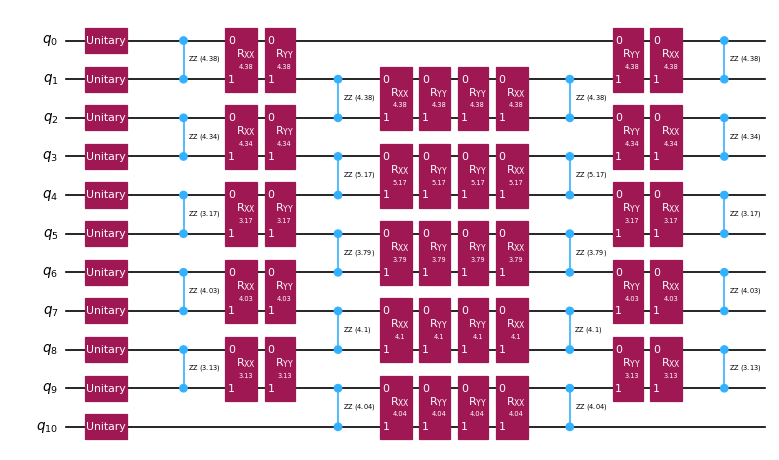

In [6]:
def first_trotter_steps(name, n_steps=2):
    # Rebuild the encoding with fewer Trotter steps, only for drawing.
    strategy = ENCODINGS[name](NUM_FEATURES)
    strategy.num_trotter_steps = n_steps
    circ = strategy._build_circuit()
    return circ.assign_parameters(encoding_pubs[name][1])


first_trotter_steps("heisenberg").draw("mpl", fold=-1, scale=0.6)

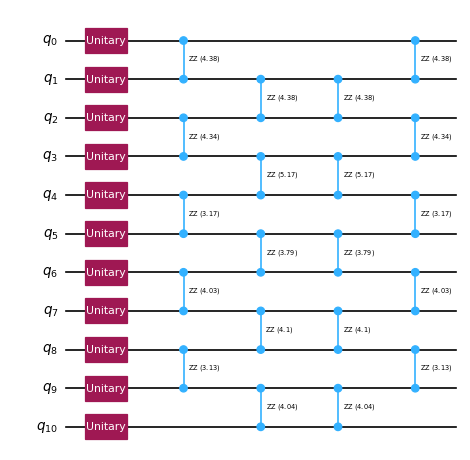

In [7]:
first_trotter_steps("zz").draw("mpl", fold=-1, scale=0.6)

## Multi-circuit quantum reservoir

The multi-circuit reservoir runs one circuit per month of the sequence. At step t the encoding receives that month's features plus the hidden state measured at step t âˆ’ 1, rescaled to `Ï€(h + 1)`; a fixed random `efficient_su2` ansatz then mixes all qubits, and the result getter's output becomes the next hidden state. The hidden state crosses between circuits classically, so each step is a separate execution and the steps of one sequence cannot run in parallel.

Each encoding therefore encodes `NUM_FEATURES + NUM_HIDDEN` values, which makes the reservoir circuits wider than the encodings above: 8 qubits for `su` and 17 for the Heisenberg and ZZ encodings.

`multi_circuit_quantum_reservoir` runs step t of every sequence in one batch, so a whole track takes `WINDOW` calls to the result getter. Below it runs on the single example sequence, once per encoding, with exact simulation.

In [8]:
def reservoir_parts(name):
    # Encoding, fixed random ansatz and PCE hidden-state getter for one multi-circuit reservoir.
    strategy = ENCODINGS[name](NUM_FEATURES + NUM_HIDDEN)
    n_qubits = strategy.n_qubits
    ansatz = efficient_su2(n_qubits, reps=1)
    rng = np.random.default_rng(SEED)
    ansatz.assign_parameters(2 * np.pi * rng.random(ansatz.num_parameters), inplace=True)
    getter = pce_result_getter(num_qubits=n_qubits, num_features=NUM_HIDDEN, num_operators=2)
    return strategy, ansatz, getter


reservoirs = {}
for name in ENCODINGS:
    strategy, ansatz, getter = reservoir_parts(name)
    features, step_circ = multi_circuit_quantum_reservoir(
        data=sequence.reset_index(drop=True),
        series_indicies=[list(range(WINDOW))],
        num_hidden_features=NUM_HIDDEN,
        ansatz=ansatz,
        encoding_strategy=strategy,
        result_getter=getter,
        return_circuit=True,
    )
    reservoirs[name] = (features, step_circ)

The final hidden state of each reservoir is its feature vector for this window (column names are the PCE strings, which differ in width between the 8- and 17-qubit circuits):

In [9]:
pd.DataFrame(
    {name: features.iloc[0].to_numpy() for name, (features, _) in reservoirs.items()},
    index=[f"h_{i}" for i in range(NUM_HIDDEN)],
).T.round(3)

,h_0,h_1,h_2,h_3,h_4,h_5
su,-0.295,-0.106,0.089,0.238,0.087,0.014
heisenberg,0.171,-0.017,0.018,-0.017,0.122,0.019
zz,0.412,0.206,-0.001,0.003,-0.002,-0.014


One step of the `su` reservoir, with its parameters unbound (`x[0]` to `x[9]` are the month's features, `x[10]` to `x[15]` the previous hidden state):

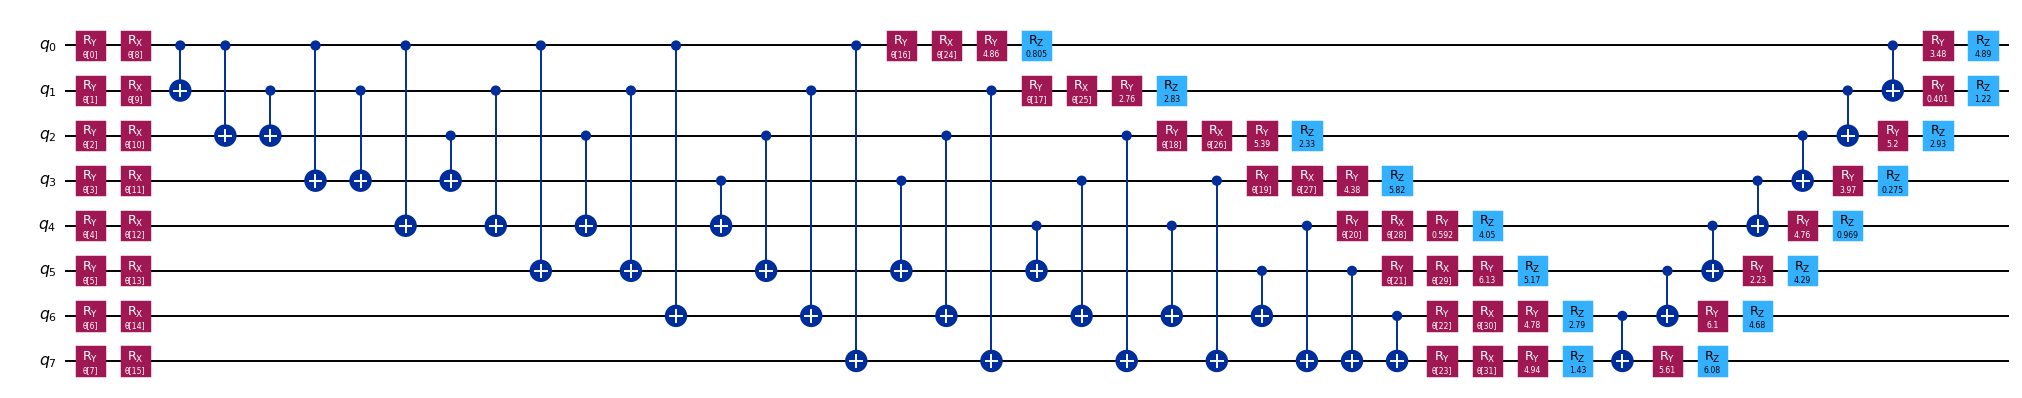

In [10]:
reservoirs["su"][1].decompose().draw("mpl", fold=-1, scale=0.7)

## Circuit depths on IBM Torino

Each circuit is transpiled once with its parameters unbound, which is what the result getters do before submitting a batch. Torino's native gates are `cz`, `rz`, `sx` and `x`, and its qubits are connected in a heavy-hex lattice, so any two-qubit gate between qubits that are not neighbours costs extra SWAPs.

- Logical depth: depth of the circuit as written, with library gates decomposed into one- and two-qubit gates.
- Torino depth: depth after transpiling to Torino's gate set and layout.
- 2Q depth: number of layers of two-qubit gates, the main driver of error on hardware.

For the multi-circuit reservoir the numbers are for one step. A sequence runs `WINDOW` steps of that same circuit, each as its own job.

In [11]:
def circuit_stats(circ):
    logical = circ.decompose(reps=3)
    isa = pass_manager.run(circ)
    ops = isa.count_ops()
    return {
        "qubits": circ.num_qubits,
        "logical depth": logical.depth(),
        "logical 2Q gates": logical.num_nonlocal_gates(),
        "Torino depth": isa.depth(),
        "Torino 2Q depth": isa.depth(lambda inst: inst.operation.num_qubits == 2),
        "Torino CZ gates": ops.get("cz", 0),
    }


rows = []
for name, (circ, _) in encoding_pubs.items():
    rows.append({"encoding": name, "circuit": "encoding only", **circuit_stats(circ)})
for name, (_, step_circ) in reservoirs.items():
    rows.append({"encoding": name, "circuit": "reservoir step", **circuit_stats(step_circ)})

depths = pd.DataFrame(rows).set_index(["encoding", "circuit"]).sort_index()
depths

qubits  logical depth  logical 2Q gates  \
encoding   circuit                                                   
heisenberg encoding only       11            205               360   
           reservoir step      17            225               592   
su         encoding only        5             11                10   
           reservoir step       8             28                35   
zz         encoding only       11             37               120   
           reservoir step      17             57               208   

                           Torino depth  Torino 2Q depth  Torino CZ gates  
encoding   circuit                                                         
heisenberg encoding only            277               62              310  
           reservoir step           323               78              512  
su         encoding only             69               20               22  
           reservoir step           220               64               96  
zz         encoding only             73               14               70  
           reservoir step           125               30              128

With the default settings:

- The `su` and ZZ encodings end up with similar total depth on Torino. ZZ has more two-qubit gates, but they only couple neighbouring qubits, which maps onto Torino's lattice without SWAPs, and consecutive ZZ rotations on the same pair merge. The `su` encoding's full entanglement needs SWAPs even on 5 qubits, so its two-qubit depth is higher.
- The Heisenberg encoding is by far the deepest, because every bond carries three non-commuting rotations in each of the `NUM_TROTTER_STEPS` steps. The transpiler resynthesises each XXÂ·YYÂ·ZZ block into at most 3 CZ gates, which is why the CZ count is lower than the logical two-qubit count.
- In every reservoir step, the `efficient_su2` ansatz uses full entanglement, which needs n(n âˆ’ 1)/2 two-qubit gates plus SWAPs on a heavy-hex lattice. For `su` and ZZ it adds more depth than the encoding itself. A `linear` or `reverse_linear` ansatz would cut this substantially.

## Executions needed by each result getter

A result getter decides what is measured, which sets both how many distinct circuits must run and how many shots each needs. Below, an "evaluation" is one circuit with one set of parameter values: one data row for `engineer_features`, one sequence for the single-circuit `quantum_reservoir`, or one step of the multi-circuit reservoir.

### What each getter measures

- `pce_result_getter`: expectation values of m Pauli strings, each acting on k qubits with the same Pauli (e.g. `XXII`, `ZIZI`).
- `single_qubit_pauli_result_getter`: âŸ¨XâŸ©, âŸ¨YâŸ© and âŸ¨ZâŸ© of every qubit, so 3n expectation values.
- `single_bit_sampler_result_getter`: the probability of reading 1 on each qubit, so n values, from computational-basis samples.
- `bitstring_probability_result_getter`: the probability of every bitstring, so 2^n values, from the same samples.

### Distinct circuits per evaluation

A measurement only reads the computational basis, so measuring X or Y means appending basis-change gates, which makes a different circuit. Observables that commute qubit by qubit can share one circuit: every string made only of X and I can be read from the same X-basis shots. Both estimator getters measure only all-X, all-Y or all-Z strings, so at most 3 circuits are needed, however many features there are. The PCE strings here need only 1: `generate_pauli_strings` lists all X strings first, so with 6 features on 8 qubits every PCE feature is an X correlation.

The current estimator path does not take advantage of this. `pce_result_getter.get_results` (and so `single_qubit_pauli_result_getter`) submits one estimator pub per observable, and the Estimator only groups observables within a pub, so each observable runs as its own circuit. Passing all observables in one pub, `(circuit, observables, params)`, would cut that to 3. Both samplers need only 1 circuit, because all their features come from the same computational-basis shots.

The cell below counts the circuits for the 8-qubit `su` reservoir step, using `group_commuting(qubit_wise=True)` to find the minimum.

In [12]:
n = reservoirs["su"][1].num_qubits
estimator_getters = {
    "pce (k=2)": pce_result_getter(num_qubits=n, num_features=NUM_HIDDEN, num_operators=2),
    "single_qubit_pauli": single_qubit_pauli_result_getter(n),
}

rows = []
for name, g in estimator_getters.items():
    rows.append({
        "result getter": name,
        "features": len(g.ops),
        "circuits as implemented": len(g.ops),
        "circuits if grouped": len(g.ops.group_commuting(qubit_wise=True)),
    })
for name, n_out in [("single_bit_sampler", n), ("bitstring_probability", 2 ** n)]:
    rows.append({"result getter": name, "features": n_out, "circuits as implemented": 1, "circuits if grouped": 1})

circuits_per_eval = pd.DataFrame(rows).set_index("result getter")
print(f"{n}-qubit circuit")
circuits_per_eval

8-qubit circuit


,features,circuits as implemented,circuits if grouped
result getter,,,
pce (k=2),6,6,1
single_qubit_pauli,24,24,3
single_bit_sampler,8,1,1
bitstring_probability,256,1,1


### Shots per circuit

Each shot gives a Â±1 outcome for every Pauli measured on that circuit, or a 0/1 outcome for every bit, so the statistical error falls as 1/âˆšS with S shots:

- Pauli expectation (estimator getters): standard error âˆš(1 âˆ’ âŸ¨PâŸ©Â²)/âˆšS â‰¤ 1/âˆšS, so a target error Îµ needs S â‰ˆ 1/ÎµÂ².
- Bit probability (single-bit sampler): standard error âˆš(p(1 âˆ’ p))/âˆšS â‰¤ 1/(2âˆšS), so S â‰ˆ 1/(4ÎµÂ²), four times fewer shots than a Pauli expectation for the same Îµ, because it is the same measurement on a scale half as wide (p = (1 âˆ’ âŸ¨ZâŸ©)/2).
- Bitstring probability: the same absolute bound holds, but with 2^n outcomes a typical probability is only about 2^âˆ’n, so an absolute error of 0.01 is larger than the value itself once n â‰¥ 7. A fixed relative error r on a probability near 2^âˆ’n needs S â‰ˆ 2^n/rÂ², which grows exponentially. With fewer shots than outcomes, most features are exactly zero.

Error mitigation adds to these numbers. The Estimator's default resilience level applies measurement twirling, and higher levels (e.g. zero-noise extrapolation) multiply the circuit count further.

### Total executions for one feature track

The table below puts the counts together for one full track: every trailing `WINDOW`-month window of the `TARGET` data, using the 8-qubit `su` reservoir step, Îµ = 0.01 for the expectation values and probabilities, and a 10% relative error for bitstring probabilities.

In [13]:
EPSILON = 0.01         # target standard error of each expectation value / probability
RELATIVE_ERROR = 0.10  # target relative error of each bitstring probability

num_windows = len(scaled) - WINDOW + 1
shots = {
    "pce (k=2)": int(np.ceil(1 / EPSILON**2)),
    "single_qubit_pauli": int(np.ceil(1 / EPSILON**2)),
    "single_bit_sampler": int(np.ceil(1 / (4 * EPSILON**2))),
    "bitstring_probability": int(np.ceil(2**n / RELATIVE_ERROR**2)),
}

budget = circuits_per_eval[["circuits as implemented", "circuits if grouped"]].copy()
budget["shots per circuit"] = pd.Series(shots)
budget["evaluations (multi-circuit)"] = num_windows * WINDOW
budget["evaluations (single-circuit)"] = num_windows
for mode in ["multi-circuit", "single-circuit"]:
    budget[f"total shots, {mode}, grouped"] = (
        budget["circuits if grouped"] * budget["shots per circuit"] * budget[f"evaluations ({mode})"]
    )

print(f"{num_windows} windows of {WINDOW} months")
budget.style.format("{:,.0f}")

756 windows of 12 months


,circuits as implemented,circuits if grouped,shots per circuit,evaluations (multi-circuit),evaluations (single-circuit),"total shots, multi-circuit, grouped","total shots, single-circuit, grouped"
result getter,,,,,,,
pce (k=2),6,1,"10,000","9,072",756,"90,720,000","7,560,000"
single_qubit_pauli,24,3,"10,000","9,072",756,"272,160,000","22,680,000"
single_bit_sampler,1,1,"2,500","9,072",756,"22,680,000","1,890,000"
bitstring_probability,1,1,"25,600","9,072",756,"232,243,200","19,353,600"


### Takeaways

- The single-bit sampler is the cheapest getter: one circuit per evaluation and a quarter of the shots of an estimator getter for the same error. Its features are linear in âŸ¨Z_iâŸ©, so it carries the same information as the Z part of `single_qubit_pauli_result_getter`, with no X or Y.
- The estimator getters cost at most 3 circuits per evaluation once observables are grouped into one pub (1 for the PCE features here). As implemented they cost one circuit per observable, 6 for PCE and 24 for single-qubit Paulis here, so grouping is the first fix to make before running on hardware.
- The bitstring getter runs one circuit, but its shot count grows as 2^n and it outputs 2^n mostly near-zero features, so it only makes sense for a few qubits.
- The multi-circuit reservoir needs `WINDOW` times as many evaluations as a single-circuit reservoir, and they are sequential within a window. `multi_circuit_quantum_reservoir` batches step t of every window into one `get_results` call, so a full track is `WINDOW` submissions rather than one per step per window.
- Exact simulation (`estimator=None` / `sampler=None`) needs no executions, but costs 2^n memory for a statevector and 4^n for a density matrix, which the single-circuit reservoir needs because of its mid-circuit resets.